# 02 Preprocessing and dimensionality reduction

In notebook 01 we found that the money columns are heavily right-skewed, that some features repeat each other, and that a few values are missing. Here we fix those problems so KMeans can work well.

**Plan**
1. Keep the 11 features chosen in notebook 01 and compare several ways of transforming and scaling them (Step 5).
2. Build the chosen option as one scikit-learn Pipeline, so the exact same steps apply to any new customer.
3. Use PCA to look at the structure of the data (Step 6).

Every code cell has a short note above it with three lines. Imports sit inside the cells that first use them.

## Step 5: Preprocessing

**What this cell does:** Loads the data, drops the ID and the six redundant features from notebook 01, and fills the few blanks with the median (inside a Pipeline step, so it is reusable).  
**What to look for:** The shape (8,950 rows by 11 columns) and zero missing values after imputation.  
**What the output means:** These 11 columns are the starting point for every option we compare. Filling blanks first means the transformers below never see a missing value.

In [1]:
# Imported here so this step only loads the libraries when it runs
from pathlib import Path
import numpy as np  # numpy does fast maths on arrays of numbers
import pandas as pd  # pandas holds and summarises the customer table
from sklearn.impute import SimpleImputer  # SimpleImputer fills blank values (here with the median)


def find_project_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the current folder until we see pyproject.toml (nbconvert runs inside notebooks/)."""
    return next(folder for folder in [start, *start.parents] if (folder / "pyproject.toml").exists())


ROOT = find_project_root()
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Decided in notebook 01 (Step 3): each of these repeats information that another kept feature already holds
FEATURES_TO_DROP = [
    "PURCHASES", "PURCHASES_TRX", "CASH_ADVANCE_TRX",
    "CASH_ADVANCE_FREQUENCY", "ONEOFF_PURCHASES_FREQUENCY", "PURCHASES_INSTALLMENTS_FREQUENCY",
]

raw = pd.read_csv(ROOT / "data" / "raw" / "credit_card.csv").set_index("CUST_ID")  # keep the ID as the row label
all_features = raw.columns.tolist()  # the 17 original features
kept_features = [name for name in all_features if name not in FEATURES_TO_DROP]  # the 11 we cluster on
print(f"{raw.shape=}, {len(kept_features)=}")

# Median imputation (decision from notebook 01). We fit on all 17 columns so Step 8 can still describe dropped columns.
imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
imputed_all = imputer.fit_transform(raw)           # learn medians and fill blanks
imputed = imputed_all[kept_features]               # the 11 clustering features, still in original units
print(f"{imputed.isna().sum().sum()=}")

raw.shape=(8950, 17), len(kept_features)=11
imputed.isna().sum().sum()=np.int64(0)


**What this cell does:** Decides which features get a log transform and checks that log1p is safe for them.  
**What to look for:** The two lists, and that the minimum of the log group is not negative.  
**What the output means:** `log1p(x)` means log(1 + x). It pulls in long right tails, and unlike a plain log it works when x is 0 (many customers have 0). It breaks for negative numbers, so we confirm there are none. The four bounded columns (shares from 0 to 1, and TENURE) stay as they are, as decided in notebook 01.

In [2]:
# Money and count columns: right-skewed, so log1p helps
log_features = [
    "BALANCE", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
    "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS",
]
# Bounded or near-constant columns: a log would be the wrong tool, we only scale them
plain_features = [name for name in kept_features if name not in log_features]
print(f"{log_features=}")
print(f"{plain_features=}")
print(f"{imputed[log_features].min().min()=}")  # must be >= 0 for log1p
assert imputed[log_features].min().min() >= 0

log_features=['BALANCE', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']
plain_features=['BALANCE_FREQUENCY', 'PURCHASES_FREQUENCY', 'PRC_FULL_PAYMENT', 'TENURE']
imputed[log_features].min().min()=np.float64(0.0)


### Comparing four options

| Option | What it does |
|---|---|
| **A. StandardScaler alone** | Subtracts the mean and divides by the standard deviation, so each feature has mean 0 and spread 1 (a *z-score*). It does not change the shape, so skew stays. |
| **B. log1p, then StandardScaler** | Log-transforms the skewed columns first, then z-scores everything. |
| **C. QuantileTransformer** | Replaces each value with its rank, mapped onto a bell curve. Forces a normal shape no matter what. |
| **D. PowerTransformer (Yeo-Johnson)** | Finds the best power for each column to make it more symmetric. Works with zeros. |

We measure two things: **skewness** after the transform (closer to 0 is better) and **the largest absolute z-score** (how far the most extreme customer is from the average, in standard deviations). A KMeans distance is dominated by features with huge z-scores.

**What this cell does:** Applies the four options to the 11 features and builds one table of skewness per feature, plus two summary rows.  
**What to look for:** Column A should keep the original skew. Look at which option brings the most skewed features close to 0, and how large the biggest z-score stays.  
**What the output means:** Skewness near 0 means a symmetric shape. A max |z| of 20 means one customer is 20 standard deviations from average, which would drag a KMeans centre. Smaller is calmer.

In [3]:
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, QuantileTransformer, StandardScaler  # the scalers and transformers we compare in this step

# Option B by hand here, to compare; the real pipeline is built further down
logged = imputed.copy()
logged[log_features] = np.log1p(logged[log_features])  # log(1 + x) on the skewed columns only

options = {
    "A: Standard only": StandardScaler().fit_transform(imputed),
    "B: log1p + Standard": StandardScaler().fit_transform(logged),
    "C: Quantile (normal)": QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=0).fit_transform(imputed),
    "D: Yeo-Johnson": PowerTransformer(method="yeo-johnson").fit_transform(imputed),
}
option_frames = {name: pd.DataFrame(values, columns=kept_features, index=imputed.index) for name, values in options.items()}

# One-liner: for each option, skew() gives per-feature skewness; concat puts them side by side as columns
skew_table = pd.concat({name: frame.skew() for name, frame in option_frames.items()}, axis=1).round(2)
summary = pd.DataFrame({
    name: {
        "mean |skew|": frame.skew().abs().mean(),   # average lopsidedness across features
        "max |z-score|": frame.abs().max().max(),   # the single most extreme value anywhere
    }
    for name, frame in option_frames.items()
}).round(2)
display(skew_table)
display(summary)

,A: Standard only,B: log1p + Standard,C: Quantile (normal),D: Yeo-Johnson
BALANCE,2.39,-0.86,-0.77,-0.12
BALANCE_FREQUENCY,-2.02,-2.02,-0.94,-1.12
ONEOFF_PURCHASES,10.05,0.19,-0.01,0.12
INSTALLMENTS_PURCHASES,7.30,-0.02,-0.17,-0.01
CASH_ADVANCE,5.17,0.26,0.13,0.19
PURCHASES_FREQUENCY,0.06,0.06,-0.01,-0.04
CREDIT_LIMIT,1.52,-0.10,0.04,-0.01
PAYMENTS,5.91,-1.78,-1.54,0.12
MINIMUM_PAYMENTS,13.85,0.27,-0.02,-0.03
PRC_FULL_PAYMENT,1.94,1.94,0.97,0.96


,A: Standard only,B: log1p + Standard,C: Quantile (normal),D: Yeo-Johnson
mean |skew|,4.83,0.95,0.61,0.43
max |z-score|,32.39,5.08,5.20,5.87


**What this cell does:** Runs a quick KMeans (k=4) on each option as a sanity check and reports the silhouette score.  
**What to look for:** Whether any option is clearly better or worse, keeping in mind these scores come from different spaces.  
**What the output means:** Silhouette (from -1 to 1, higher means tighter, better-separated clusters) is not fully comparable across different transforms, so we use it only as a sanity check, not as the decision rule. The decision rests on skewness, extremes and interpretability.

In [4]:
from sklearn.cluster import KMeans  # KMeans groups customers around k centre points
from sklearn.metrics import silhouette_score  # silhouette score: how well separated the groups are (-1 to 1)

sanity = {}
for name, frame in option_frames.items():
    labels = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(frame)
    # sample_size keeps this fast; random_state makes the sample repeatable
    sanity[name] = silhouette_score(frame, labels, sample_size=4000, random_state=0)
pd.Series(sanity, name="silhouette (k=4)").round(3).to_frame()

,silhouette (k=4)
A: Standard only,0.196
B: log1p + Standard,0.212
C: Quantile (normal),0.253
D: Yeo-Johnson,0.194


**What this cell does:** Draws before-and-after histograms for three of the most skewed features: raw, Option A, and Option B.  
**What to look for:** The raw and A histograms (same shape, one huge spike near 0), versus B (a spread-out shape).  
**What the output means:** This is the visual proof of what the skewness table says: scaling alone does not change the shape, a log transform does.

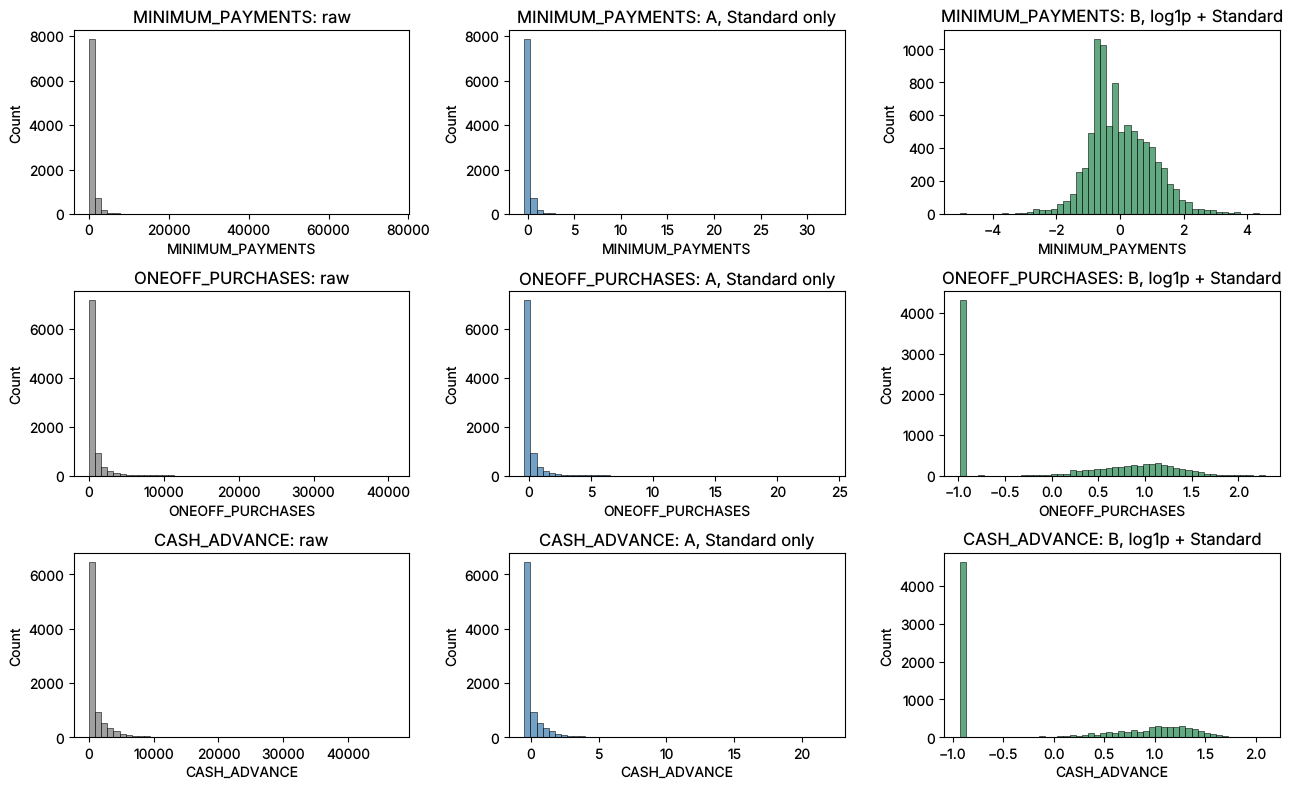

In [5]:
import matplotlib.pyplot as plt  # imported here because plotting starts in this cell
import seaborn as sns  # seaborn draws statistical plots on top of matplotlib

examples = ["MINIMUM_PAYMENTS", "ONEOFF_PURCHASES", "CASH_ADVANCE"]
fig, axes = plt.subplots(len(examples), 3, figsize=(13, 8))
for row, feature in enumerate(examples):
    sns.histplot(imputed[feature], bins=50, ax=axes[row, 0], color="gray")
    axes[row, 0].set_title(f"{feature}: raw")
    sns.histplot(option_frames["A: Standard only"][feature], bins=50, ax=axes[row, 1], color="steelblue")
    axes[row, 1].set_title(f"{feature}: A, Standard only")
    sns.histplot(option_frames["B: log1p + Standard"][feature], bins=50, ax=axes[row, 2], color="seagreen")
    axes[row, 2].set_title(f"{feature}: B, log1p + Standard")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "transform_comparison.png", dpi=110)
plt.show()

### What the comparison shows

| Option | Mean abs skew | Largest absolute z-score | Comment |
|---|---|---|---|
| A. Standard only | 4.83 | 32.4 | Shape unchanged. One customer sits 32 standard deviations out, so a handful of giants would steer KMeans. |
| **B. log1p + Standard** | **0.95** | **5.1** | Calmest extremes of all four. The seven log-transformed columns average about 0.5 skew. |
| C. Quantile (normal) | 0.61 | 5.2 | Looks good, but it ranks customers and *discards the size of the gaps*. It also smears the big pile of zeros into an artificial slope. |
| D. Yeo-Johnson | 0.43 | 5.9 | Lowest skew and a close second. Each column gets its own hidden power, which is harder to explain and to repeat by hand. |

**Reading the B column honestly.** The 0.95 average is held up by four columns we deliberately did not log: `TENURE` (-2.9), `BALANCE_FREQUENCY` (-2.0) and `PRC_FULL_PAYMENT` (1.9), which are bounded and have no better fix, and `PURCHASES_FREQUENCY`, which is already fine. `PAYMENTS` is slightly over-corrected (-1.8) and `BALANCE` a little (-0.9).

**The histograms add a warning that the skew number hides.** After `log1p`, `ONEOFF_PURCHASES` and `CASH_ADVANCE` look like a tall spike at the far left plus a bell curve. The spike is customers with exactly zero: 4,302 (48%) for one-off purchases, 4,628 (52%) for cash advance and 3,916 (44%) for installments. No transform removes this, and it should not be removed: "never uses this feature" is real behaviour and probably the main thing that separates the segments. It just means the skew number looks better than the shape really is.

(The sanity silhouette for C is the highest at 0.253. We do not treat that as a reason to choose it: the scores come from different spaces, and C's gain partly comes from squeezing the data into a tidier shape.)

### Decision: Option B (log1p, then StandardScaler)

- It has the **lowest extreme values** (largest |z| of 5.1), which is the property that protects KMeans from a few giants.
- It is **easy to explain and to repeat**: "we took the log of the money columns, then put everything on the same scale". A business reader can follow that, and a new customer can be treated with the same formula.
- It **keeps the zeros as a clear group** instead of smearing them.
- **Runner-up:** Yeo-Johnson (D). In notebook 03 we check that using D instead gives similar clusters.

Below we build B as a proper Pipeline.

**What this cell does:** Builds the final preprocessing as one scikit-learn Pipeline: impute, then (log1p + scale) for skewed columns and (scale) for bounded columns.  
**What to look for:** The output shape (8,950 by 11), column means near 0 and standard deviations near 1.  
**What the output means:** A Pipeline bundles every step. Fitted once, it can be saved and used on any new customer in exactly the same way: it reuses the training medians, the training scales, and applies the same log. ColumnTransformer sends different columns through different steps.

In [6]:
from sklearn.compose import ColumnTransformer  # ColumnTransformer sends different columns through different steps
from sklearn.pipeline import Pipeline  # Pipeline chains steps so they run the same way on any data

# Branch 1: log1p then z-score, for the skewed money columns
log_branch = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
# Branch 2: only z-score, for the bounded columns
plain_branch = Pipeline([("scale", StandardScaler())])

# Send each group of columns through its own branch; remainder="drop" throws away the 6 redundant columns
column_steps = ColumnTransformer(
    transformers=[("log", log_branch, log_features), ("plain", plain_branch, plain_features)],
    remainder="drop",
    verbose_feature_names_out=False,  # keep the plain column names
)

full_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),  # fills blanks using the training medians
    ("transform", column_steps),                   # log1p + scale, or scale only, depending on the column
]).set_output(transform="pandas")  # keep column names between steps

**What this cell does:** Fits the pipeline on the raw data and checks the result.  
**What to look for:** Shape (8,950, 11), no missing values, mean near 0 and standard deviation near 1 for every column.  
**What the output means:** This is the table KMeans will use. Each column is now on the same scale, so no single feature can dominate the distance.

In [7]:
scaled = full_pipeline.fit_transform(raw)  # learn medians, scales; return the scaled table
print(f"{scaled.shape=}, {scaled.isna().sum().sum()=}")
scaled.describe().loc[["mean", "std", "min", "max"]].round(2)

scaled.shape=(8950, 11), scaled.isna().sum().sum()=np.int64(0)


,BALANCE,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,BALANCE_FREQUENCY,PURCHASES_FREQUENCY,PRC_FULL_PAYMENT,TENURE
mean,0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.06,-0.99,-1.09,-0.93,-5.08,-4.16,-5.04,-3.70,-1.22,-0.53,-4.12
max,1.83,2.28,2.16,2.09,2.70,2.64,4.55,0.52,1.27,2.89,0.36


**What this cell does:** Tests that the pipeline treats a brand new customer the same way, including a blank value.  
**What to look for:** The transformed row should have finite numbers and the same column order as the training table.  
**What the output means:** This proves reuse: in real life a new customer arrives with raw numbers and maybe a blank, and the saved pipeline can score them.

In [8]:
new_customer = raw.iloc[[0]].copy()
new_customer["MINIMUM_PAYMENTS"] = np.nan  # pretend this value is missing
print(full_pipeline.transform(new_customer).round(2).T.rename(columns={new_customer.index[0]: "scaled value"}))

CUST_ID                 scaled value
BALANCE                        -1.21
ONEOFF_PURCHASES               -0.99
INSTALLMENTS_PURCHASES          0.39
CASH_ADVANCE                   -0.93
CREDIT_LIMIT                   -1.45
PAYMENTS                       -0.82
MINIMUM_PAYMENTS               -0.14
BALANCE_FREQUENCY              -0.25
PURCHASES_FREQUENCY            -0.81
PRC_FULL_PAYMENT               -0.53
TENURE                          0.36


**What this cell does:** Saves the fitted pipeline, the scaled data and the imputed original-unit data to data/processed/.  
**What to look for:** That three files exist.  
**What the output means:** Notebook 03 loads the scaled table to cluster, and notebook 04 loads the original-unit table so explanations are in real dollars. Saving them means each notebook can run on its own.

In [9]:
import joblib  # imported here because this is the only place we save a model object

joblib.dump(full_pipeline, PROCESSED_DIR / "preprocessing_pipeline.joblib")   # the fitted recipe
scaled.to_csv(PROCESSED_DIR / "credit_card_scaled.csv")                       # for clustering
imputed_all.to_csv(PROCESSED_DIR / "credit_card_imputed_original_units.csv")  # all 17 columns, for profiling and SHAP
print(sorted(path.name for path in PROCESSED_DIR.glob("*") if path.name != ".gitkeep"))

['cluster_labels.csv', 'cluster_names.json', 'credit_card_imputed_original_units.csv', 'credit_card_scaled.csv', 'kmeans_k6.joblib', 'preprocessing_pipeline.joblib']


---
## Step 6: Dimensionality reduction (for visualization and for checking structure)

*Dimensionality reduction* squeezes many columns into a few while keeping as much information as possible. **PCA** (principal component analysis) finds new axes, called components, that are combinations of the original columns. Component 1 captures the most variation, component 2 the next most, and so on, and they are uncorrelated with each other.

**Important:** we use PCA to *look* at the data and to check how much structure there is. We do **not** cluster on the PCA output. KMeans runs on all 11 scaled features.

**What this cell does:** Runs PCA on the scaled data and plots the explained variance per component and the cumulative total.  
**What to look for:** How quickly the bars shrink, and how many components reach 80% and 90% of the variance.  
**What the output means:** *Explained variance* is the share of the total spread in the data that one component captures. If a few components capture most of it, the data has simple structure. If it needs many, the information is spread over many features.

components_for_80=6, components_for_90=7


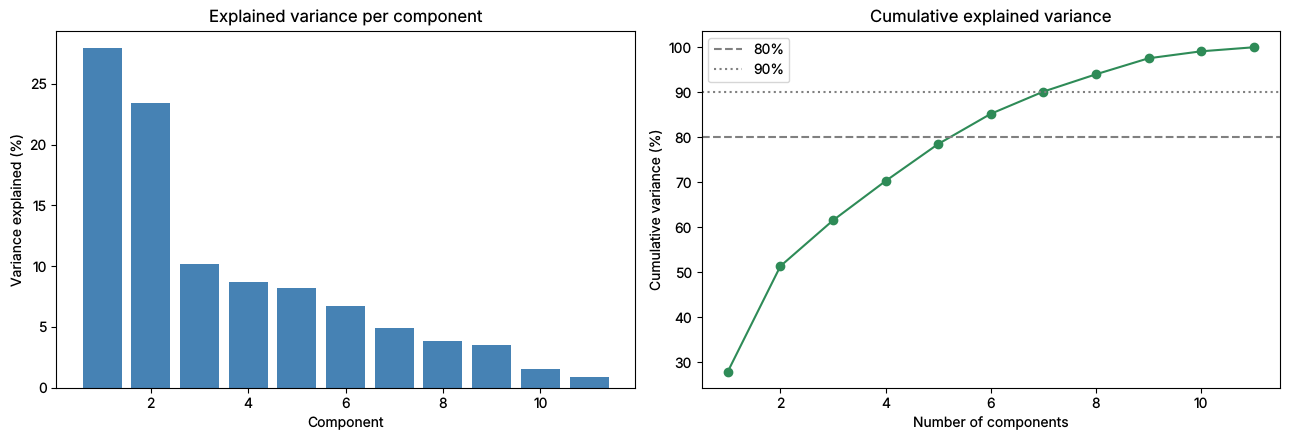

,explained_%,cumulative_%
PC1,28.0,28.0
PC2,23.4,51.4
PC3,10.2,61.5
PC4,8.7,70.3
PC5,8.2,78.5
PC6,6.7,85.2
PC7,4.9,90.1
PC8,3.8,94.0
PC9,3.6,97.6
PC10,1.5,99.1


In [10]:
from sklearn.decomposition import PCA  # PCA squeezes the 11 features into a few components for viewing

pca = PCA(random_state=0).fit(scaled)  # keep all 11 components for now
explained = pca.explained_variance_ratio_
cumulative = explained.cumsum()
components_for_80 = int(np.searchsorted(cumulative, 0.80) + 1)  # first position where the running total passes 80%
components_for_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print(f"{components_for_80=}, {components_for_90=}")

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
left.bar(range(1, len(explained) + 1), explained * 100, color="steelblue")
left.set(xlabel="Component", ylabel="Variance explained (%)", title="Explained variance per component")
right.plot(range(1, len(cumulative) + 1), cumulative * 100, marker="o", color="seagreen")
right.axhline(80, color="gray", linestyle="--", label="80%")
right.axhline(90, color="gray", linestyle=":", label="90%")
right.set(xlabel="Number of components", ylabel="Cumulative variance (%)", title="Cumulative explained variance")
right.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pca_variance.png", dpi=110)
plt.show()
pd.DataFrame({"explained_%": (explained * 100).round(1), "cumulative_%": (cumulative * 100).round(1)}, index=[f"PC{i}" for i in range(1, 12)])

**What this cell does:** Shows which original features drive the first three components (their loadings).  
**What to look for:** The largest positive and negative numbers in each column.  
**What the output means:** A loading says how much a feature contributes to a component. If PC1 is led by purchase features, then moving along PC1 means 'buys more or less'. This helps us read the 2D plot.

In [11]:
loadings = pd.DataFrame(pca.components_[:3].T, index=kept_features, columns=["PC1", "PC2", "PC3"]).round(2)
loadings.sort_values("PC1", key=abs, ascending=False)

,PC1,PC2,PC3
BALANCE,0.54,0.04,-0.14
CREDIT_LIMIT,0.46,0.03,-0.15
INSTALLMENTS_PURCHASES,0.36,-0.29,0.06
PAYMENTS,0.35,0.20,-0.39
PURCHASES_FREQUENCY,0.28,0.29,0.31
PRC_FULL_PAYMENT,-0.26,0.26,0.25
CASH_ADVANCE,0.22,0.22,0.55
ONEOFF_PURCHASES,-0.11,0.49,-0.29
MINIMUM_PAYMENTS,-0.10,0.54,-0.29
TENURE,0.10,0.17,0.36


**What this cell does:** Projects every customer onto the first two components and plots them, once as points and once as a density map.  
**What to look for:** Is there one blob, several blobs, or a smooth cloud? Are there dense spots and thin edges?  
**What the output means:** This plot is for seeing structure, not for final clustering. Two components keep only part of the information, so groups that overlap here may still be separate in the full 11 dimensions, and groups that look separate here might not be.

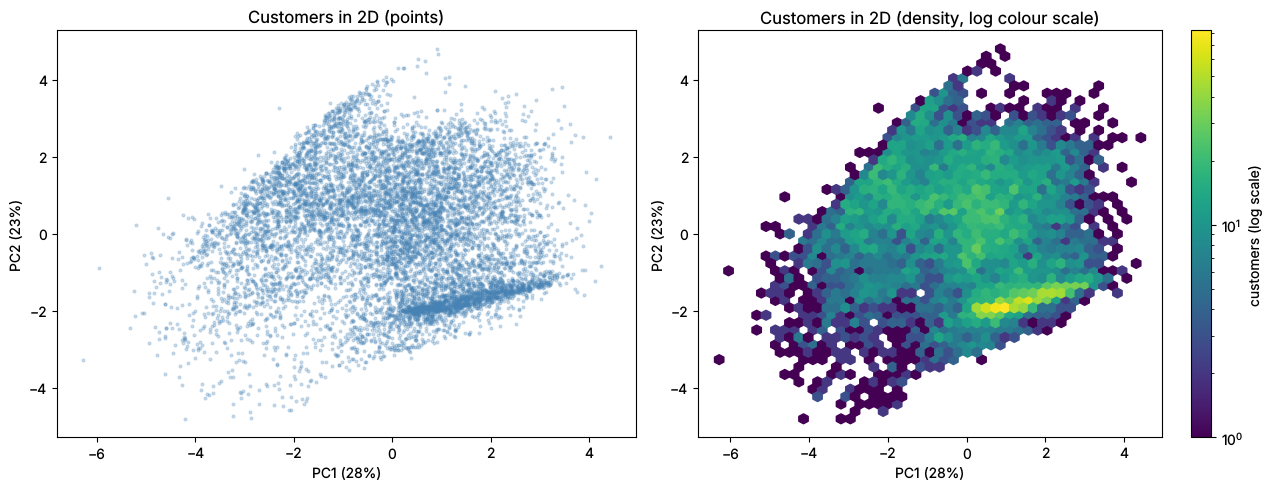

In [12]:
coordinates = pca.transform(scaled)[:, :2]  # first two components for each customer

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
left.scatter(coordinates[:, 0], coordinates[:, 1], s=4, alpha=0.25, color="steelblue")
left.set(xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})", title="Customers in 2D (points)")
density = right.hexbin(coordinates[:, 0], coordinates[:, 1], gridsize=45, cmap="viridis", mincnt=1, bins="log")
right.set(xlabel=f"PC1 ({explained[0]:.0%})", ylabel=f"PC2 ({explained[1]:.0%})", title="Customers in 2D (density, log colour scale)")
fig.colorbar(density, ax=right, label="customers (log scale)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pca_2d.png", dpi=110)
plt.show()

### What PCA tells us

- **The data is not simple.** The first two components hold only 51.4% of the variation. It takes 6 components to pass 80% (85.2%) and 7 to pass 90%. This is why we must not cluster on the 2D picture: it throws away about half of the information. KMeans uses all 11 scaled features.
- **What the first two axes mean** (from the loadings): PC1 (28%) rises with `BALANCE` (0.54), `CREDIT_LIMIT` (0.46), `INSTALLMENTS_PURCHASES` and `PAYMENTS`, so it reads as **account size and activity**. PC2 (23%) is led by `MINIMUM_PAYMENTS` (0.54) and `ONEOFF_PURCHASES` (0.49), so it mostly separates **big one-off buyers from those who do not buy**.
- **There are no clean islands.** The cloud is one continuous mass, so clusters will touch each other. Expect modest scores from the metrics in Step 7 (roughly 0.2 to 0.3 for silhouette, not 0.7) and treat the segments as regions of a continuum.
- **One structure does stand out.** The dense streak at the lower right is 1,297 customers (14%). All of them use cash advances, 94% make no one-off purchases, and the median customer in it has zero purchases of any kind. That is a **cash-advance-only** group, and it is the first segment we can already name.